# Introduction to AI — Exercise Solutions

**Notebook status:** execution below is saved from a local run. Python 3.13.14; deterministic, synthetic examples; no API credentials or external services.

## Section A — Introduction

Worked solutions to the separate practice notebook. Try the exercises first; alternate answers are valid when assumptions are clear.

**Prerequisites:** Python 3.11+, basic values and function calls. Install notebook support with `python -m pip install -e ".[notebooks]"`. **Objectives:** trace the code, explain its output, identify limitations, and suggest a real-world safety boundary. Full theory: [lesson notes](../lessons/01_introduction_to_artificial_intelligence.md).

In [1]:
import sys
import matplotlib

print(f"Python {sys.version.split()[0]} | matplotlib {matplotlib.__version__}")

Python 3.13.14 | matplotlib 3.10.8


This environment cell records the actual interpreter and plotting-library versions used for this notebook execution. Minimum compatible dependency versions are documented in the course `pyproject.toml`.

## Section B — Beginner explanation

A complete solution includes reasoning and limitations, not merely code that runs.

The code cells are runnable Python. Explanations before and after each cell distinguish the expected behavior from the actual output saved by this execution.

## Section C — First Python example

Read the inputs and operations before running. The output below is captured from actual execution.

In [2]:
def fit_centroids(rows):
    if not rows:
        raise ValueError("training examples are required")
    sums, counts = {}, {}
    for value, label in rows:
        sums[label] = sums.get(label, 0.0) + value
        counts[label] = counts.get(label, 0) + 1
    return {label: sums[label] / counts[label] for label in sums}

centers = fit_centroids([(10, "normal"), (14, "normal"), (70, "review"), (90, "review")])
prediction = min(centers, key=lambda label: abs(60-centers[label]))
print("means:", centers, "| prediction for 60:", prediction)

means: {'normal': 12.0, 'review': 80.0} | prediction for 60: review


**Line-by-line walkthrough:** Reject empty data, accumulate sums/counts by label, compute means, then choose the nearest mean to 60. This tiny deterministic result does not establish operational performance.

The output immediately above is actual saved execution output. It occurs because the code uses the displayed deterministic input.

## Section D — Intermediate examples

This example adds a more realistic data structure or evaluation step. Inputs are documented in the code.

In [3]:
def threshold_review(value, threshold=75.0):
    if threshold < 0:
        raise ValueError("threshold must be non-negative")
    return value >= threshold

print([threshold_review(v) for v in (74.9, 75.0, 75.1)])

[False, True, True]


This cell's output is the result of the displayed computation. New Python operations are explained in the code and can be inspected interactively.

## Section E — Advanced examples

This example adds an edge case, metric, or validation concern. Consider both computational behavior and decision consequences.

In [4]:
actual, predicted = [1, 1, 0, 0, 0], [1, 0, 0, 0, 0]
tp = sum(a == p == 1 for a, p in zip(actual, predicted))
fn = sum(a == 1 and p == 0 for a, p in zip(actual, predicted))
tn = sum(a == p == 0 for a, p in zip(actual, predicted))
print(f"TP={tp}, FN={fn}, TN={tn}; recall={tp/(tp+fn):.1%}; accuracy={(tp+tn)/len(actual):.1%}")

TP=1, FN=1, TN=3; recall=50.0%; accuracy=80.0%


Interpret each result in the context of the toy data; do not generalize the score to real deployments.

## Section F — Real-world applications

Example application: synthetic network engineering telemetry and read-only triage. The same principles apply to AI, data science, cloud monitoring, automation, and production software.

In [5]:
recommendation = {"text": "inspect interface counters",
                 "evidence": ["synthetic latency elevated"],
                 "device_write": False, "approval_required": True}
print(recommendation)

{'text': 'inspect interface counters', 'evidence': ['synthetic latency elevated'], 'device_write': False, 'approval_required': True}


No live network is contacted. Any production system needs data provenance, permissions, observability, human review, and a rollback/disable plan.

## Section G — Visualization

The chart below is rendered and embedded in this notebook's saved outputs. It uses the small synthetic demonstration data.

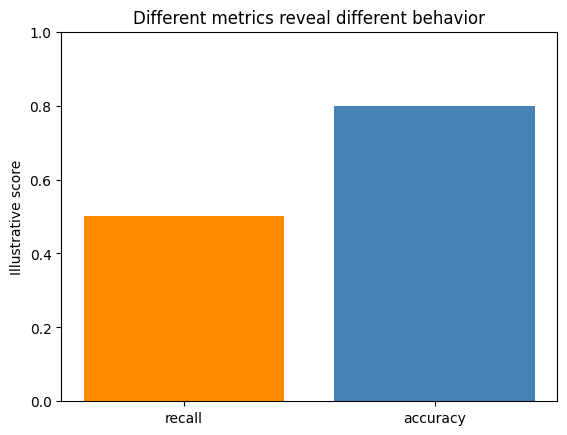

In [6]:
import matplotlib.pyplot as plt
plt.bar(["recall", "accuracy"], [0.5, 0.8], color=["darkorange", "steelblue"])
plt.ylim(0, 1)
plt.ylabel("Illustrative score")
plt.title("Different metrics reveal different behavior")
plt.show()

The figure supports visual intuition only; it is not validation evidence.

## Section H — Debugging and common mistakes

The following code intentionally reaches an invalid-input path but catches the exception, leaving an inspectable message rather than an unhandled notebook error.

In [7]:
def validate_training(rows):
    if not rows:
        raise ValueError("training data must not be empty")

try:
    validate_training([])
except ValueError as error:
    print("Correctly rejected:", error)
print("Valid fit:", fit_centroids([(1, "a"), (3, "a")]))

Correctly rejected: training data must not be empty
Valid fit: {'a': 2.0}


Reject malformed input explicitly; never substitute a success-shaped prediction or silently perform an operational action.

## Section I — Exercises

Compare your answers with `../solutions/lesson_01_solutions.md`. Add tests for invalid input and explain why model recommendations cannot grant themselves authorization.

Attempt these before using the separate `07_Exercise_Solutions.ipynb`.

## Section J — Summary and knowledge check

Check assumptions, use appropriate held-out data, and keep permission controls outside the model. Explain one risk that remains in this design.

**Review:** What are the input, output, assumptions, failure mode, and safe fallback? Continue with the full theory notes and then AI problem formulation: goals, state, actions, constraints, costs, and success criteria.